## Step 2.1 — Load packages

Every package below plays a specific role in the workflow. Read the comments.

In [4]:
%pip install matplotlib pandas numpy seaborn scikit-learn

  Obtaining dependency information for matplotlib from https://files.pythonhosted.org/packages/04/93/0d239bde12b308262265c2d98909b2f0ecad2b5deeae96241642e822e9c7/matplotlib-3.11.2-cp312-cp312-win_amd64.whl.metadata
     ---------------------------------------- 0.0/80.3 kB ? eta -:--:--
     ---------------------------------------- 0.0/80.3 kB ? eta -:--:--
     ----- ---------------------------------- 10.2/80.3 kB ? eta -:--:--
     ----- ---------------------------------- 10.2/80.3 kB ? eta -:--:--
     -------------- ----------------------- 30.7/80.3 kB 330.3 kB/s eta 0:00:01
     ----------------------------- -------- 61.4/80.3 kB 409.6 kB/s eta 0:00:01
     -------------------------------------- 80.3/80.3 kB 500.2 kB/s eta 0:00:00
  Obtaining dependency information for pandas from https://files.pythonhosted.org/packages/10/72/06aefff8fe5efc5e1ca8bfb2695b648a435358f6dc224d4e40159314181a/pandas-3.1.0-cp312-cp312-win_amd64.whl.metadata
  Obtaining dependency information for numpy from

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 23.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [12]:

# This line helps Jupyter show the plots under the code cells
%matplotlib inline

# --- Libraries for working with data ---
import pandas as pd            # Used to work with tables and data
import numpy as np             # Used for mathematical operations

# --- Libraries for drawing plots ---
import matplotlib.pyplot as plt    # Used to create different types of plots
import seaborn as sns              # Used to make plots look better and easier to read

# --- Tools for preparing data ---
from sklearn.preprocessing import LabelEncoder, StandardScaler
# LabelEncoder changes text values into numbers
# StandardScaler helps put numerical data on the same scale

# --- Tools for selecting important features ---
from sklearn.feature_selection import SelectKBest, f_classif
# SelectKBest selects the most important features from the data
# f_classif helps measure the relationship between features and the target column (Risk)

# --- Settings for displaying results ---
sns.set_style("whitegrid")                 # Sets a grid style for the plots
plt.rcParams["figure.figsize"] = (10, 5)   # Sets the default size of the plots
pd.set_option("display.width", 100)        # Makes the displayed data wider
pd.set_option("display.max_columns", 20)   # Sets the maximum number of columns to display

print("All packages loaded successfully.")

All packages loaded successfully.


## Step 2.2 — Load the dataset

In [14]:
# The CSV file is in the same folder as this notebook.
# The link below can be used to download the file if needed.
# https://raw.githubusercontent.com/tatsath/fin-ml/master/Chapter%206%20-%20Sup.%20Learning%20-%20Classification%20models/german_credit_data.csv

DATA_PATH = "EDA.csv"

# Read the CSV file and store the data in a DataFrame
dataset = pd.read_csv(DATA_PATH)

# Print the number of rows and columns in the dataset
print(f"Dataset loaded: {dataset.shape[0]} rows, {dataset.shape[1]} columns")

Dataset loaded: 1000 rows, 10 columns


## Step 3 — Exploratory Data Analysis (EDA)

### 3.1 Descriptive statistics

Before doing anything else with a new dataset, we should always look at it: how
big is it, what type is each column, are there missing values, and what do the
numbers roughly look like?

In [15]:
# Show the first 5 rows of the dataset to see what the data looks like
dataset.head()

,Age,Sex,Job,Housing,SavingAccounts,CheckingAccount,CreditAmount,Duration,Purpose,Risk
0,67,male,2,own,NaN,little,1169,6,radio/TV,good
1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,49,male,1,own,little,NaN,2096,12,education,good
3,45,male,2,free,little,little,7882,42,furniture/equipment,good
4,53,male,2,free,little,little,4870,24,car,bad


In [16]:
# Show the number of rows and columns in the dataset
print("Shape (rows, columns):", dataset.shape)

Shape (rows, columns): (1000, 10)


In [17]:
# Show the data type of each column in the dataset
# This helps us know which columns contain numbers and which contain text
dataset.dtypes

Age                int64
Sex                  str
Job                int64
Housing              str
SavingAccounts       str
CheckingAccount      str
CreditAmount       int64
Duration           int64
Purpose              str
Risk                 str
dtype: object

In [18]:
# Show a summary of the numerical columns in the dataset
# This includes the count, average, minimum, maximum, and other values
# It helps us understand the data and notice any unusual values
dataset.describe()

,Age,Job,CreditAmount,Duration
count,1000.000000,1000.000000,1000.000000,1000.000000
mean,35.546000,1.904000,3271.258000,20.903000
std,11.375469,0.653614,2822.736876,12.058814
min,19.000000,0.000000,250.000000,4.000000
25%,27.000000,2.000000,1365.500000,12.000000
50%,33.000000,2.000000,2319.500000,18.000000
75%,42.000000,2.000000,3972.250000,24.000000
max,75.000000,3.000000,18424.000000,72.000000


In [19]:
# Show a summary of the text columns in the dataset
# This includes the number of values, unique values, and most common value
dataset.describe(exclude="number")

,Sex,Housing,SavingAccounts,CheckingAccount,Purpose,Risk
count,1000,1000,817,606,1000,1000
unique,2,3,4,3,8,2
top,male,own,little,little,car,good
freq,690,713,603,274,337,700


In [20]:
# Count the missing values in each column
# This helps us know if there are empty values before using the data

missing_counts = dataset.isna().sum()

print("Missing values per column:\n")
print(missing_counts)

Missing values per column:

Age                  0
Sex                  0
Job                  0
Housing              0
SavingAccounts     183
CheckingAccount    394
CreditAmount         0
Duration             0
Purpose              0
Risk                 0
dtype: int64


In [21]:
# Count how many cases belong to each Risk category
# This helps us understand how the Risk values are distributed
print(dataset["Risk"].value_counts())
print()

# Show the percentage of each Risk category
print(dataset["Risk"].value_counts(normalize=True).round(3) * 100, "% of total")

Risk
good    700
bad     300
Name: count, dtype: int64

Risk
good    70.0
bad     30.0
Name: proportion, dtype: float64 % of total


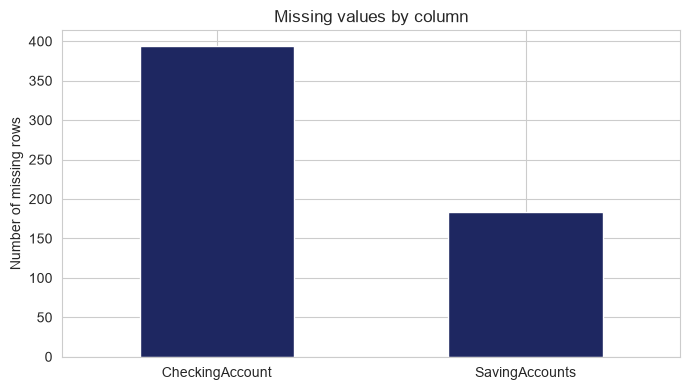

In [22]:
# Create a bar chart to show the columns that have missing values
missing_counts = dataset.isna().sum()
missing_counts = missing_counts[missing_counts > 0].sort_values(ascending=False)

plt.figure(figsize=(7, 4))  # Set the size of the chart
missing_counts.plot(kind="bar", color="#1E2761")  # Draw a bar chart
plt.title("Missing values by column")  # Add a title
plt.ylabel("Number of missing rows")  # Add a label to the y-axis
plt.xticks(rotation=0)  # Keep the column names straight
plt.tight_layout()  # Adjust the chart layout
plt.show()  # Display the chart

# The chart shows which columns have missing values
# SavingAccounts and CheckingAccount have missing values
# We will handle these missing values during data cleaning

### 3.2 Data visualization

#### Univariate plots
Study each attribute on its own first -- this is the fastest way to learn what a
dataset actually looks like before comparing variables to each other.

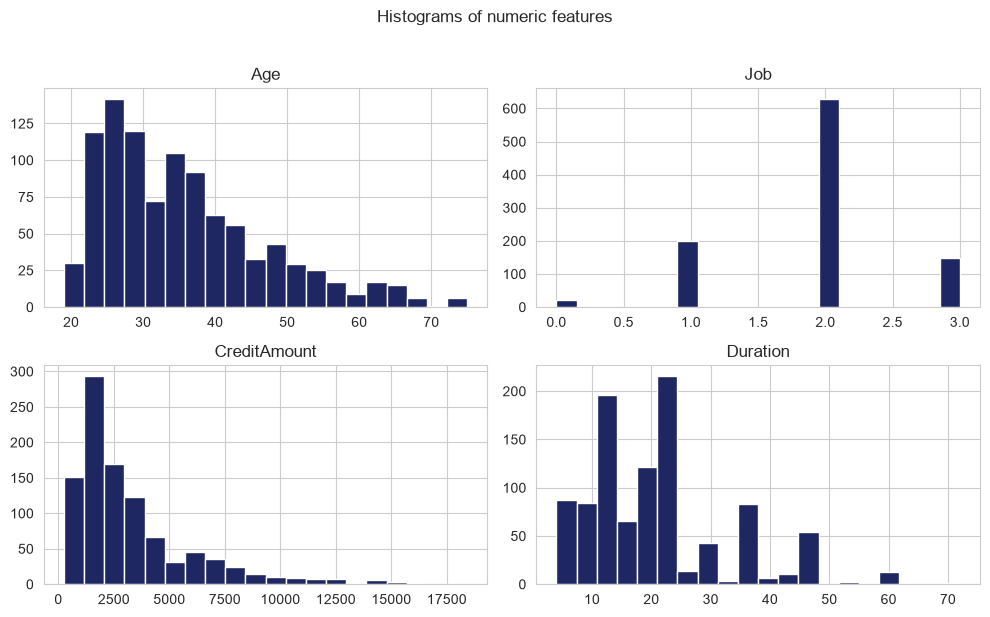

In [23]:
# Create histograms for the numerical columns to see how the values are distributed
# This helps us understand the data and notice any unusual values
numeric_cols = ["Age", "Job", "CreditAmount", "Duration"]

# Draw a histogram for each numerical column
dataset[numeric_cols].hist(figsize=(10, 6), bins=20, color="#1E2761", edgecolor="white")

plt.suptitle("Histograms of numeric features", y=1.02)  # Add a title to all histograms
plt.tight_layout()  # Adjust the layout
plt.show()  # Display the histograms

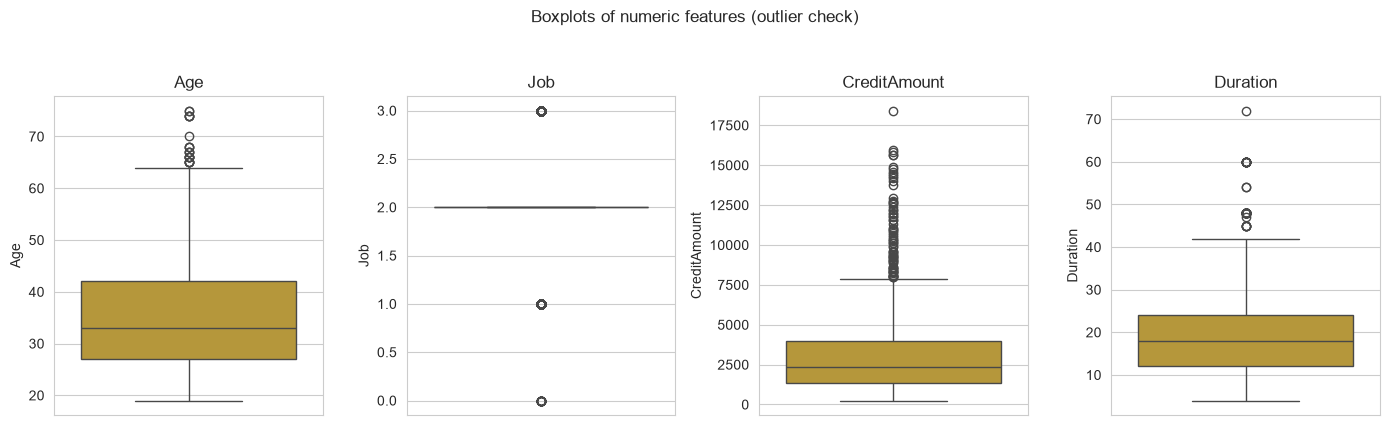

In [24]:
# Create boxplots to check for unusual values in the numerical columns
# The box shows the middle values, and the points outside may be outliers
fig, axes = plt.subplots(1, len(numeric_cols), figsize=(14, 4))

for ax, col in zip(axes, numeric_cols):
    sns.boxplot(y=dataset[col], ax=ax, color="#C9A227")  # Draw a boxplot for each column
    ax.set_title(col)  # Add the column name as a title

plt.suptitle("Boxplots of numeric features (outlier check)", y=1.05)  # Add a main title
plt.tight_layout()  # Adjust the layout
plt.show()  # Display the boxplots

# CreditAmount and Duration have some high values
# These values may be outliers, but they are not always errors

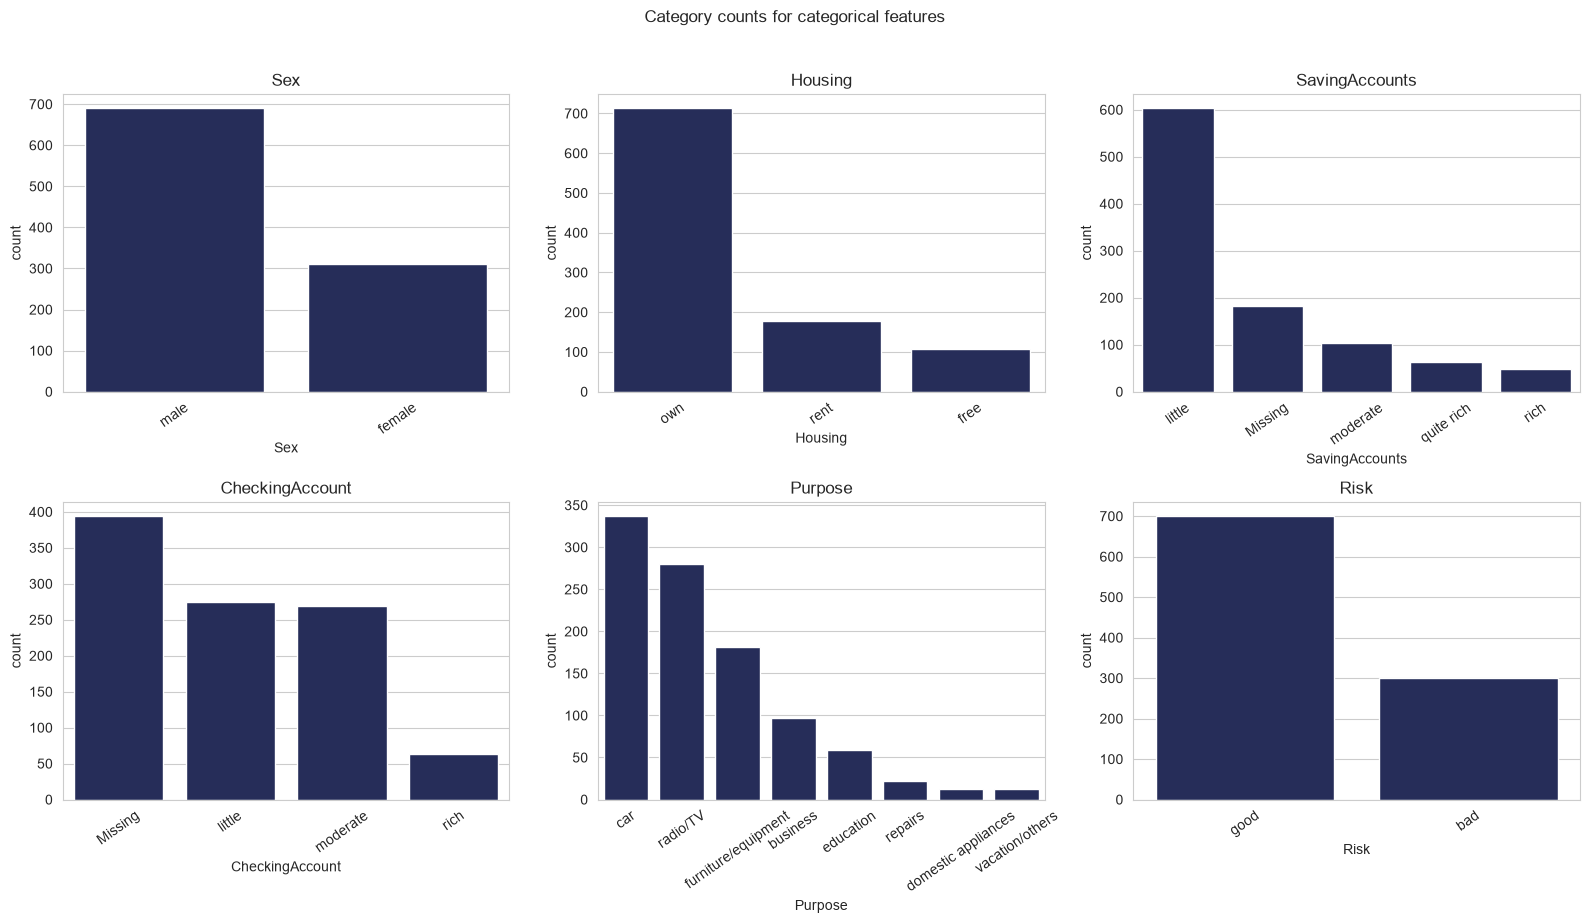

In [25]:
# Create count plots to see how many values are in each category
categorical_cols = ["Sex", "Housing", "SavingAccounts", "CheckingAccount", "Purpose", "Risk"]

# Create a figure with 6 plots
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for ax, col in zip(axes, categorical_cols):
    # Replace missing values with the word "Missing"
    col_data = dataset[col].fillna("Missing")

    # Arrange the categories from most common to least common
    order = col_data.value_counts().index

    # Draw a count plot for each column
    sns.countplot(x=col_data, order=order, ax=ax, color="#1E2761")
    ax.set_title(col)  # Add the column name as a title
    ax.tick_params(axis="x", rotation=35)  # Rotate the labels to make them easier to read

plt.suptitle("Category counts for categorical features", y=1.02)  # Add the main title
plt.tight_layout()  # Adjust the layout
plt.show()  # Display the plots

#### Multivariate plots
Now look at relationships **between** variables -- this is where useful patterns
for a future model usually show up.

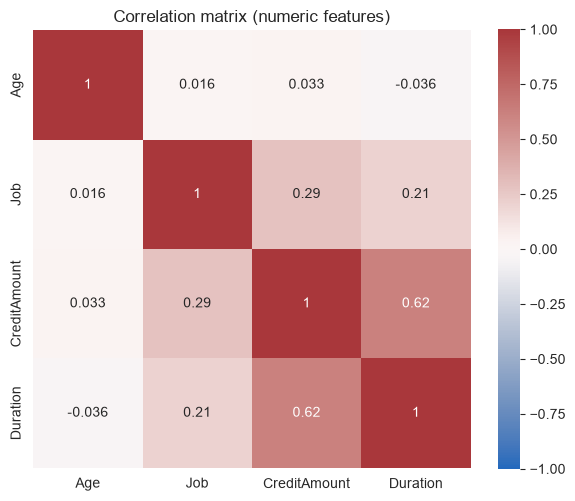

In [26]:
# Create a heatmap to show the relationship between numerical columns
# Values close to 1 or -1 show a strong relationship
# Values close to 0 show a weak relationship
plt.figure(figsize=(6, 5))

# Calculate the correlation between the numerical columns
correlation = dataset[numeric_cols].corr()

# Draw the heatmap and show the correlation values
sns.heatmap(correlation, vmin=-1, vmax=1, annot=True, cmap="vlag", square=True)

plt.title("Correlation matrix (numeric features)")  # Add a title
plt.tight_layout()  # Adjust the layout
plt.show()  # Display the heatmap

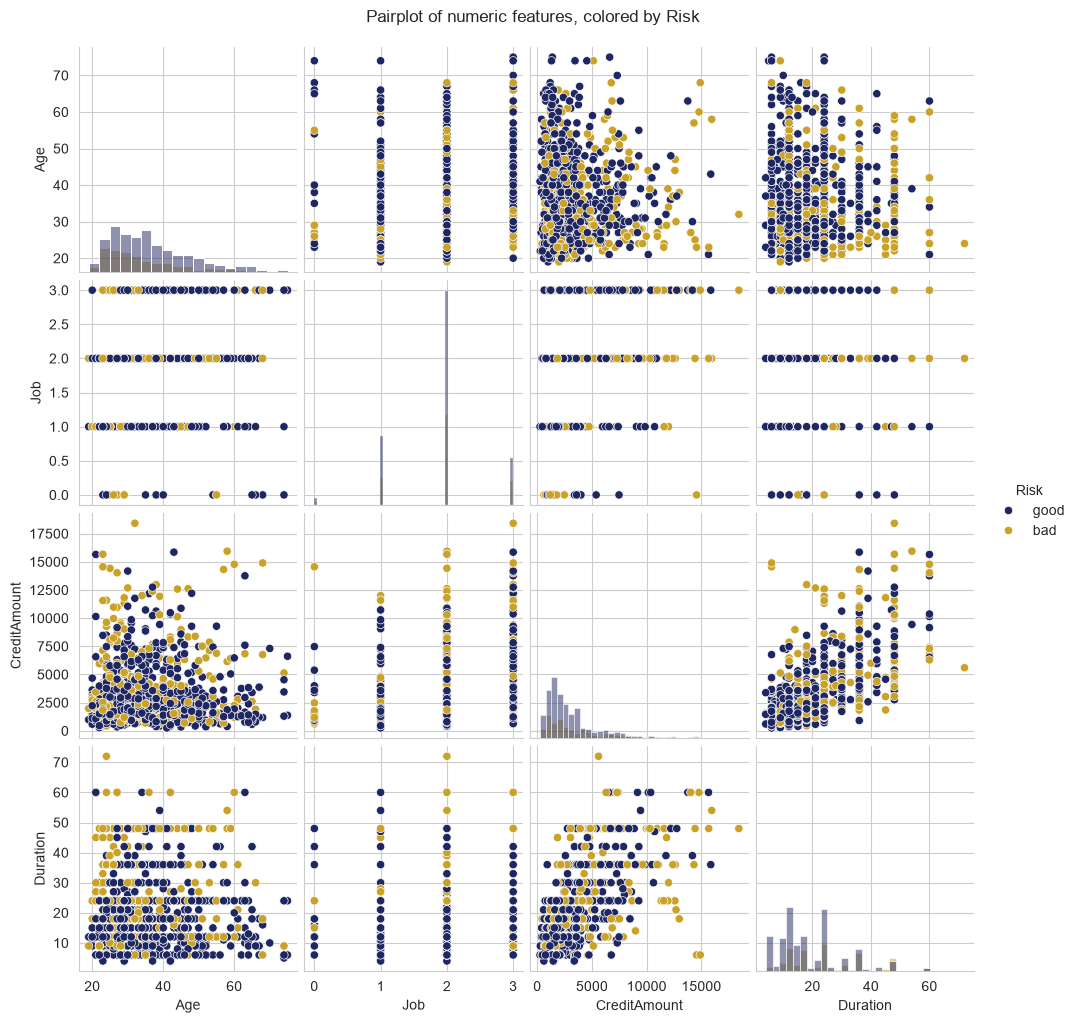

In [28]:
# Create pairplots to compare the numerical columns with each other
# The colors help us compare the different Risk categories
sns.pairplot(dataset, vars=numeric_cols, hue="Risk", palette={"good": "#1E2761", "bad": "#C9A227"}, diag_kind="hist")

plt.suptitle("Pairplot of numeric features, colored by Risk", y=1.02)  # Add a main title
plt.show()  # Display the plots

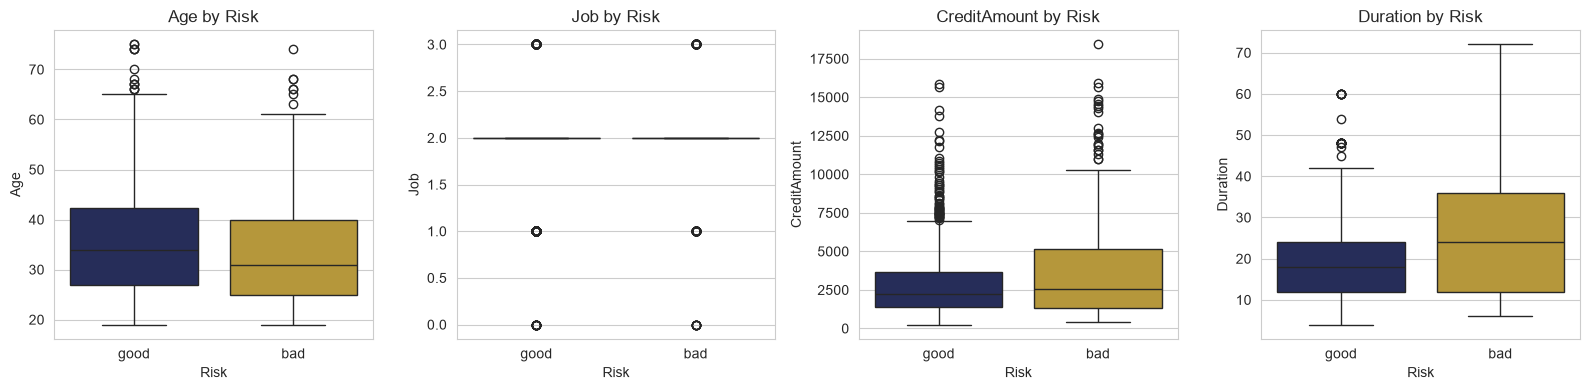

In [29]:
# Create boxplots to compare numerical values between good and bad Risk categories
# This helps us see if there are differences between the two groups
fig, axes = plt.subplots(1, len(numeric_cols), figsize=(16, 4))

for ax, col in zip(axes, numeric_cols):
    # Draw a boxplot for each numerical column based on Risk
    sns.boxplot(data=dataset, x="Risk", y=col, hue="Risk",
                palette={"good": "#1E2761", "bad": "#C9A227"}, legend=False, ax=ax)
    ax.set_title(f"{col} by Risk")  # Add a title to each plot

plt.tight_layout()  # Adjust the layout
plt.show()  # Display the plots

# The plots help us compare the numerical values for each Risk category
# We can check if CreditAmount and Duration are different between the two groups

## Step 4 — Data Preparation

### 4.1 Data cleaning — handling missing values

We saw earlier that `SavingAccounts` and `CheckingAccount` have missing values.
For this dataset, a missing entry most likely means the applicant does not have
that type of account at all -- so instead of dropping rows (which would throw
away otherwise-good data), we'll fill the missing values with an explicit
`"none"` category.

In [30]:
# Make a copy of the dataset to keep the original data unchanged
df_clean = dataset.copy()

# Replace missing values in SavingAccounts with "none"
df_clean["SavingAccounts"] = df_clean["SavingAccounts"].fillna("none")

# Replace missing values in CheckingAccount with "none"
df_clean["CheckingAccount"] = df_clean["CheckingAccount"].fillna("none")

# Check if there are any missing values left in the dataset
print("Remaining missing values:\n")
print(df_clean.isna().sum())

Remaining missing values:

Age                0
Sex                0
Job                0
Housing            0
SavingAccounts     0
CheckingAccount    0
CreditAmount       0
Duration           0
Purpose            0
Risk               0
dtype: int64


### 4.2 Data transformation — encoding & scaling

Machine learning tools generally expect **numbers**, not text, and often work
better when numeric features share a similar scale. So we:

1. **Encode** categorical (text) columns into numbers.
2. **Scale** numeric columns so no single feature dominates just because of its
   raw magnitude (e.g. `CreditAmount` is in the thousands, `Job` is 0–3).

In [31]:
# Change the text values in categorical columns into numbers
df_encoded = df_clean.copy()

# List the columns that contain text categories
categorical_cols_all = ["Sex", "Housing", "SavingAccounts", "CheckingAccount", "Purpose", "Risk"]

# Save the encoders so we can use them later if needed
encoders = {}

for col in categorical_cols_all:
    le = LabelEncoder()  # Create a LabelEncoder
    df_encoded[col] = le.fit_transform(df_clean[col])  # Convert text into numbers
    encoders[col] = le  # Save the encoder for this column
    print(f"{col:16s} -> {list(le.classes_)}")  # Show the categories in each column

Sex              -> ['female', 'male']
Housing          -> ['free', 'own', 'rent']
SavingAccounts   -> ['little', 'moderate', 'none', 'quite rich', 'rich']
CheckingAccount  -> ['little', 'moderate', 'none', 'rich']
Purpose          -> ['business', 'car', 'domestic appliances', 'education', 'furniture/equipment', 'radio/TV', 'repairs', 'vacation/others']
Risk             -> ['bad', 'good']


In [32]:
# --- Scale numeric columns ---
# StandardScaler transforms each numeric column to have mean 0 and std dev 1.
scaler = StandardScaler()
numeric_cols_to_scale = ["Age", "Job", "CreditAmount", "Duration"]

df_scaled = df_encoded.copy()
df_scaled[numeric_cols_to_scale] = scaler.fit_transform(df_encoded[numeric_cols_to_scale])

# Compare a couple of rows before vs. after scaling, to see what changed.
print("Before scaling:")
print(df_encoded[numeric_cols_to_scale].head(3))
print("\nAfter scaling (mean ~0, std ~1):")
print(df_scaled[numeric_cols_to_scale].head(3).round(3))

Before scaling:
   Age  Job  CreditAmount  Duration
0   67    2          1169         6
1   22    2          5951        48
2   49    1          2096        12

After scaling (mean ~0, std ~1):
     Age    Job  CreditAmount  Duration
0  2.766  0.147        -0.745    -1.236
1 -1.191  0.147         0.950     2.248
2  1.183 -1.384        -0.417    -0.739


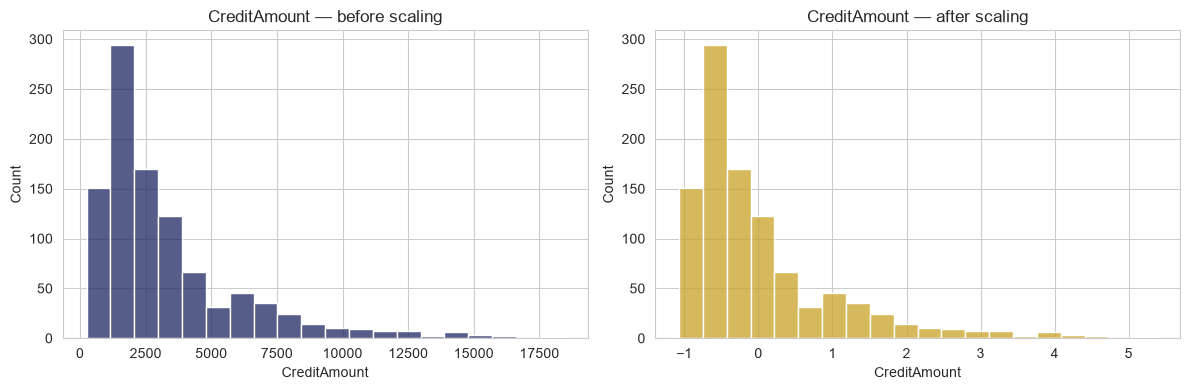

In [33]:
# Compare CreditAmount before and after scaling
# This helps us see how scaling changes the values
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Show CreditAmount before scaling
sns.histplot(df_encoded["CreditAmount"], bins=20, ax=axes[0], color="#1E2761")
axes[0].set_title("CreditAmount — before scaling")

# Show CreditAmount after scaling
sns.histplot(df_scaled["CreditAmount"], bins=20, ax=axes[1], color="#C9A227")
axes[1].set_title("CreditAmount — after scaling")

plt.tight_layout()  # Adjust the layout
plt.show()  # Display the histograms

### 4.3 Feature selection

Now that every column is numeric, we can score each feature on how strongly it
relates to `Risk`. This does **not** train a predictive model -- it only ranks
features, which is useful information before modeling begins in a later class.

In [34]:
# Separate the input columns from the Risk column
X = df_scaled.drop(columns=["Risk"])
y = df_scaled["Risk"]

# SelectKBest is used to check the importance of each feature
# A higher score means the feature may help distinguish between Risk categories
selector = SelectKBest(score_func=f_classif, k="all")   # Calculate scores for all features
selector.fit(X, y)  # Calculate the scores using the data

# Create a table showing each feature and its score
feature_scores = pd.DataFrame({
    "Feature": X.columns,
    "Score": selector.scores_
}).sort_values("Score", ascending=False).reset_index(drop=True)

# Display the features sorted from highest score to lowest
feature_scores

,Feature,Score
0,CheckingAccount,111.721482
1,Duration,48.333790
2,SavingAccounts,33.948465
3,CreditAmount,24.482366
4,Age,8.356995
5,Sex,5.720350
6,Purpose,3.745234
7,Job,1.070584
8,Housing,0.372463


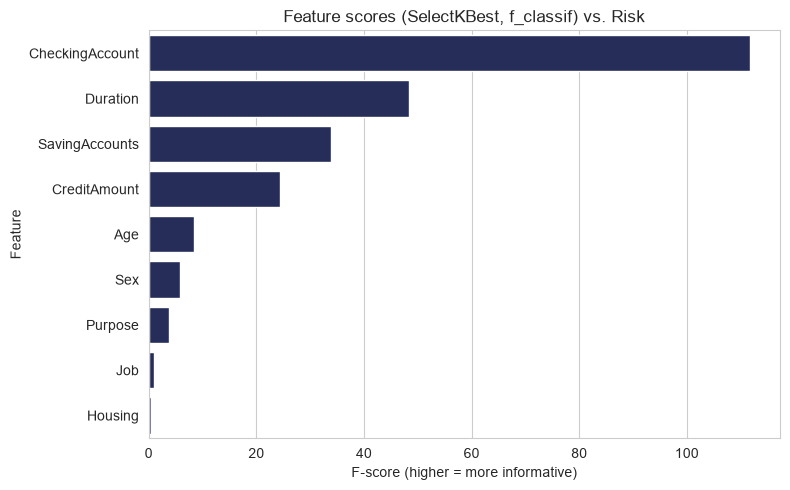

In [35]:
# Create a bar chart to compare the scores of the features
# Higher scores mean the features may be more useful for predicting Risk
plt.figure(figsize=(8, 5))

# Draw a bar for each feature
sns.barplot(data=feature_scores, x="Score", y="Feature", color="#1E2761")

plt.title("Feature scores (SelectKBest, f_classif) vs. Risk")  # Add a title
plt.xlabel("F-score (higher = more informative)")  # Add a label to the x-axis
plt.tight_layout()  # Adjust the layout
plt.show()  # Display the chart

# This step helps us identify useful features before building a model
# It does not train a model or make predictions

## Summary

In this notebook we practiced the **data side** of a machine learning project on
a real finance dataset, without training any model:

- **Loaded packages** — pandas, numpy, matplotlib, seaborn, and a few
  scikit-learn preprocessing/feature-selection tools.
- **Loaded the dataset** — the German Credit Risk dataset (1,000 loan
  applicants, 10 columns).
- **Explored the data** — shape, data types, summary statistics, missing
  values, and the balance of the `Risk` column.
- **Visualized the data** — histograms, boxplots and count plots (univariate),
  plus a correlation heatmap, pairplot and grouped boxplots (multivariate).
- **Cleaned the data** — filled missing `SavingAccounts` / `CheckingAccount`
  values with an explicit `"none"` category.
- **Transformed the data** — label-encoded categorical columns and scaled
  numeric columns with `StandardScaler`.
- **Selected features** — ranked every feature by its statistical relationship
  to `Risk` using `SelectKBest`.

**Next class:** splitting this prepared data into training and test sets, and
finally training and evaluating a model.

---
*Dataset: German Credit Risk data, via the companion repository for Hariom
Tatsat, Sahil Puri & Brad Lookabaugh, "Machine Learning and Data Science
Blueprints for Finance" (O'Reilly, 2020). Original source: UCI Machine Learning
Repository, Statlog (German Credit Data).*